## HW02 - Single and Two-Qubit Quantum Circuits in Qiskit

**Name:** Kane Joshua Ibanez  
**Course:** QQCOMP01  
**Section:** S01

In [1]:

!pip install qiskit
!pip install pylatexenc
!pip install qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 50.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 29.4 MB/s  0:00:00


In [2]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


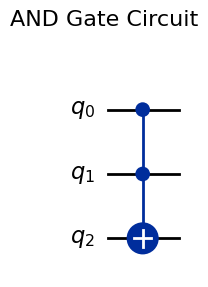

Input (A B),00,01,10,11
Statevector,|000>,|001>,|010>,|111>
Output,0,0,0,1
Expected,0,0,0,1
Match?,Yes,Yes,Yes,Yes


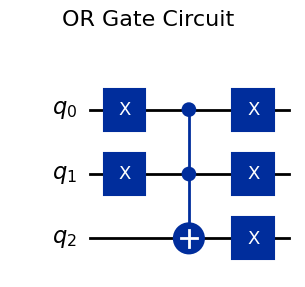

Input (A B),00,01,10,11
Statevector,|000>,|101>,|110>,|111>
Output,0,1,1,1
Expected,0,1,1,1
Match?,Yes,Yes,Yes,Yes


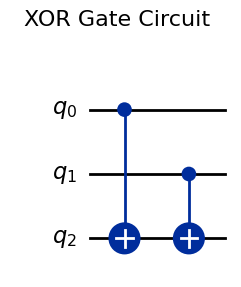

Input (A B),00,01,10,11
Statevector,|000>,|101>,|110>,|011>
Output,0,1,1,0
Expected,0,1,1,0
Match?,Yes,Yes,Yes,Yes


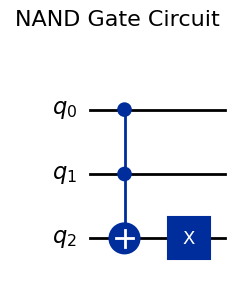

Input (A B),00,01,10,11
Statevector,|100>,|101>,|110>,|011>
Output,1,1,1,0
Expected,1,1,1,0
Match?,Yes,Yes,Yes,Yes


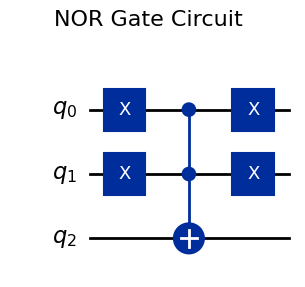

Input (A B),00,01,10,11
Statevector,|100>,|001>,|010>,|011>
Output,1,0,0,0
Expected,1,0,0,0
Match?,Yes,Yes,Yes,Yes


In [7]:
#Qubit layout: q0 = B, q1 = A, q2 = the ancilla output (initially |0>).
#Each circuit implements |A, B, 0> -> |A, B, f(A, B)> without changing A or B.

expected_tables = {
    "AND":  {"00": "0", "01": "0", "10": "0", "11": "1"},
    "OR":   {"00": "0", "01": "1", "10": "1", "11": "1"},
    "XOR":  {"00": "0", "01": "1", "10": "1", "11": "0"},
    "NAND": {"00": "1", "01": "1", "10": "1", "11": "0"},
    "NOR":  {"00": "1", "01": "0", "10": "0", "11": "0"},
}
def prepare_inputs(bits):
    circuit = QuantumCircuit(3)
    if bits[0] == "1":  # A is q1
        circuit.x(1)
    if bits[1] == "1":  # B is q0
        circuit.x(0)
    return circuit

def read_basis_state(state):
    index = int(np.argmax(np.abs(state.data)))
    if not np.isclose(abs(state.data[index]), 1.0):
        raise ValueError("The circuit did not produce a basis state.")
    return format(index, "03b")  # Qiskit displays q2 q1 q0.

def test_gate(gate_name, add_gate):
    circuit_for_drawing = QuantumCircuit(3)
    add_gate(circuit_for_drawing)

    #label
    fig = circuit_for_drawing.draw("mpl")
    fig.suptitle(f"{gate_name} Gate Circuit", fontsize=16, y=1.05)
    display(fig)

    results = {}
    for bits in ["00", "01", "10", "11"]:
        circuit = prepare_inputs(bits)
        add_gate(circuit)
        basis_state = read_basis_state(Statevector.from_instruction(circuit))
        output_bit = basis_state[0]  #q2 is the leftmost displayed bit.
        expected_bit = expected_tables[gate_name][bits]
        results[bits] = {
            "Statevector": f"|{basis_state}>",
            "Output": output_bit,
            "Expected": expected_bit,
            "Match?": "Yes" if output_bit == expected_bit else "No",
        }

    table = pd.DataFrame(results)
    table.columns.name = "Input (A B)"
    display(table)
    assert all(row["Match?"] == "Yes" for row in results.values())
    return table

def add_and_gate(circuit):
    circuit.ccx(0, 1, 2)

def add_or_gate(circuit):  # OR(A,B) = NOT(AND(NOT A, NOT B)).
    circuit.x(0)
    circuit.x(1)
    circuit.ccx(0, 1, 2)
    circuit.x(2)
    circuit.x(0)
    circuit.x(1)

def add_xor_gate(circuit):
    circuit.cx(0, 2)
    circuit.cx(1, 2)

def add_nand_gate(circuit):
    circuit.ccx(0, 1, 2)
    circuit.x(2)

def add_nor_gate(circuit): # NOR(A,B) = AND(NOT A, NOT B).
    circuit.x(0)
    circuit.x(1)
    circuit.ccx(0, 1, 2)
    circuit.x(0)
    circuit.x(1)

for name, implementation in [
    ("AND", add_and_gate),
    ("OR", add_or_gate),
    ("XOR", add_xor_gate),
    ("NAND", add_nand_gate),
    ("NOR", add_nor_gate),
]:
    test_gate(name, implementation)

In [ ]:
# PART B
np.random.seed(123)

states = []
for i in range(5):
    v = np.random.randn(2) + 1j*np.random.randn(2)
    v = v/np.linalg.norm(v)
    states.append(Statevector(v))

values = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi,
          5*np.pi/4, 3*np.pi/2, 7*np.pi/4]

def u3_result(theta, phi, lam, state):
    qc = QuantumCircuit(1)
    qc.u(theta, phi, lam, 0)
    return state.evolve(qc)

def gate_result(name, state):
    qc = QuantumCircuit(1)
    if name == "X":
        qc.x(0)
    if name == "Y":
        qc.y(0)
    if name == "Z":
        qc.z(0)
    if name == "H":
        qc.h(0)
    return state.evolve(qc)

def works(theta, phi, lam, name):
    answer = True
    for state in states:
        u3_state = u3_result(theta, phi, lam, state)
        gate_state = gate_result(name, state)
        same_result = u3_state.equiv(gate_state, atol=1e-8)    # assures me that tolerance allows for tiny numerical rounding errors.
        if same_result == False:
            answer = False
    return answer

x_answers = []
y_answers = []
z_answers = []
h_answers = []

for theta in values:
    for phi in values:
        for lam in values:
            if works(theta, phi, lam, "X"):
                x_answers.append((theta, phi, lam))
            if works(theta, phi, lam, "Y"):
                y_answers.append((theta, phi, lam))
            if works(theta, phi, lam, "Z"):
                z_answers.append((theta, phi, lam))
            if works(theta, phi, lam, "H"):
                h_answers.append((theta, phi, lam))

def show_answers(name, answers):
    rows = []
    for answer in answers:
        theta = round(answer[0]/np.pi, 2)
        phi = round(answer[1]/np.pi, 2)
        lam = round(answer[2]/np.pi, 2)
        rows.append([theta, phi, lam])
    table = pd.DataFrame(rows, columns=["theta/pi", "phi/pi", "lambda/pi"])
    print("\n", name, "gate", sep="")
    display(table)

show_answers("X", x_answers)
show_answers("Y", y_answers)
show_answers("Z", z_answers)
show_answers("H", h_answers)

   print("X hand solution found by loop:", hand_x in x_answers)
   print("Y hand solution found by loop:", hand_y in y_answers)
   print("Z hand solution found by loop:", hand_z in z_answers)
   print("H hand solution found by loop:", hand_h in h_answers)



Xgate


,theta/pi,phi/pi,lambda/pi
0,1.0,0.00,1.00
1,1.0,0.25,1.25
2,1.0,0.50,1.50
3,1.0,0.75,1.75
4,1.0,1.00,0.00
5,1.0,1.25,0.25
6,1.0,1.50,0.50
7,1.0,1.75,0.75



Ygate


,theta/pi,phi/pi,lambda/pi
0,1.0,0.00,0.00
1,1.0,0.25,0.25
2,1.0,0.50,0.50
3,1.0,0.75,0.75
4,1.0,1.00,1.00
5,1.0,1.25,1.25
6,1.0,1.50,1.50
7,1.0,1.75,1.75



Zgate


,theta/pi,phi/pi,lambda/pi
0,0.0,0.00,1.00
1,0.0,0.25,0.75
2,0.0,0.50,0.50
3,0.0,0.75,0.25
4,0.0,1.00,0.00
5,0.0,1.25,1.75
6,0.0,1.50,1.50
7,0.0,1.75,1.25



Hgate


,theta/pi,phi/pi,lambda/pi
0,0.5,0.0,1.0
1,1.5,1.0,0.0
